In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.interpolate import interp1d

In [6]:
# =================================================================
# === CONFIGURATION: Update these values as needed ==============
# =================================================================

# Folder containing your CSV files (e.g., "saudaveis" or "doentes")
INPUT_FOLDER_NAME = "saudaveis" 

# Label to assign to all spectra in this folder (e.g., 'healthy' or 'sick')
LABEL = "healthy"

# === MODEL INPUT PARAMETERS (FIXED FOR RAMANNET TRANSFER LEARNING) ===
TARGET_WAVENUMBER_MIN = 400.0  # Start of the desired spectral window
TARGET_WAVENUMBER_MAX = 1800.0 # End of the desired spectral window
TARGET_POINTS = 1000           # Fixed length M required by the RamanNet model

# === OUTPUT FILES ===
OUTPUT_X = f"X_raman_{LABEL}.npy"
OUTPUT_Y = f"y_labels_{LABEL}.npy"

# =================================================================
# === CORE PROCESSING LOGIC =======================================
# =================================================================

def process_folder(input_folder, target_points, min_shift, max_shift, label):
    """
    Loads, cleans, interpolates, and prepares Raman spectra for a single group.
    
    Args:
        input_folder (str): Path to the folder containing CSV files.
        target_points (int): The desired output length of each spectrum.
        min_shift (float): The minimum wavenumber for the target grid.
        max_shift (float): The maximum wavenumber for the target grid.
        label (str): The label to assign to all spectra.
        
    Returns:
        tuple: (numpy array of processed spectra X, numpy array of labels y)
    """
    
    spectra = []
    labels = []
    preview_done = False
    
    # Create the standardized X-axis grid for interpolation
    wavenumbers_grid = np.linspace(min_shift, max_shift, target_points)
    
    print(f"--- Processing folder: {input_folder} (Target points: {target_points}) ---")
    
    # Check if the folder exists
    if not os.path.isdir(input_folder):
        print(f"Error: Input folder '{input_folder}' not found.", file=sys.stderr)
        return np.array([]), np.array([])
        
    
    for file_name in os.listdir(input_folder):
        if file_name.endswith(".csv"):
            file_path = os.path.join(input_folder, file_name)

            df = None
            
            # --- DELIMITER DETECTION AND LOADING ---
            try:
            # Auto-detect separator
                df = pd.read_csv(file_path, sep=None, engine='python', skip_blank_lines=True)
            except Exception as e:
                print(f"⚠️ Could not read {file_name}: {e}")
                continue

            if df.shape[1] < 2:
                print(f"⚠️ Skipping {file_name}: only {df.shape[1]} column(s) found.")
                continue

            
            # Clean column names by stripping whitespace (important for semicolon files)
            #df.columns = df.columns.astype(str).str.strip()
            
            # Ensure first two columns are used for shift and intensity
            # Coerce to numeric, turning any non-numeric data into NaN
            df['shift'] = pd.to_numeric(df.iloc[:, 0], errors='coerce')
            df['intensity'] = pd.to_numeric(df.iloc[:, 1], errors='coerce')
            
            # Drop any rows that couldn't be converted to numbers (e.g., headers or metadata)
            df_clean = df.dropna(subset=['shift', 'intensity'])
            
            shift = df_clean['shift'].to_numpy()
            intensity = df_clean['intensity'].to_numpy()

            if len(shift) < 2:
                print(f"Skipping {file_name}: insufficient numeric data points.", file=sys.stderr)
                continue
            
            # 1. CREATE INTERPOLATOR: Create a function that can estimate intensity 
            #    at any point within the original range.
            interp_func = interp1d(shift, intensity, kind='cubic', fill_value='extrapolate')

            # 2. RESAMPLE: Use the interpolator on the standardized 1000-point grid.
            intensity_resampled = interp_func(wavenumbers_grid)

            # Show a small preview for the first valid file
            if not preview_done:
                print(f"\n📄 Preview from file: {file_name}")
                print(f"Original points: {len(shift)}. Resampled points: {len(intensity_resampled)}")
                print(f"Resampled Shift Range: {wavenumbers_grid[0]:.2f} - {wavenumbers_grid[-1]:.2f} cm⁻¹")
                preview_df = pd.DataFrame({
                    "Raman Shift (cm⁻¹)": wavenumbers_grid[:10],
                    "Intensity": intensity_resampled[:10]
                })
                print(preview_df)
                preview_done = True
            
            spectra.append(intensity_resampled)
            labels.append(label)

    # Final conversion to NumPy arrays
    X = np.array(spectra)
    y = np.array(labels)
    
    return X, y

In [7]:
# --- Execution ---
if __name__ == "__main__":
    
    # 1. Determine the input folder path
    input_folder_path = os.path.join(os.getcwd(), INPUT_FOLDER_NAME)

    # 2. Process the data
    X_processed, y_processed = process_folder(
        input_folder=input_folder_path,
        target_points=TARGET_POINTS,
        min_shift=TARGET_WAVENUMBER_MIN,
        max_shift=TARGET_WAVENUMBER_MAX,
        label=LABEL
    )

    if X_processed.size > 0:
        # 3. Save arrays
        np.save(OUTPUT_X, X_processed)
        np.save(OUTPUT_Y, y_processed)

        print(f"\n=========================================================================")
        print(f"✅ SUCCESS: Processed {X_processed.shape[0]} spectra for '{LABEL}' group.")
        print(f"✅ Saved intensity matrix X: {OUTPUT_X} ({X_processed.shape})")
        print(f"✅ Saved labels y: {OUTPUT_Y} ({y_processed.shape})")
        print(f"Data is now ready for combining and training.")
        print(f"=========================================================================")
    else:
        print("\n❌ FAILED: No spectra were successfully processed.", file=sys.stderr)

--- Processing folder: C:\Users\Rima\OneDrive - Instituto Politécnico de Lisboa\Exp dataset raman\Urine samples\saudaveis (Target points: 1000) ---

📄 Preview from file: P1_saudavel.csv
Original points: 2048. Resampled points: 1000
Resampled Shift Range: 400.00 - 1800.00 cm⁻¹
   Raman Shift (cm⁻¹)  Intensity
0          400.000000   0.016292
1          401.401401   0.018206
2          402.802803   0.020009
3          404.204204   0.021702
4          405.605606   0.023273
5          407.007007   0.024755
6          408.408408   0.026110
7          409.809810   0.027246
8          411.211211   0.028091
9          412.612613   0.028689

✅ SUCCESS: Processed 7 spectra for 'healthy' group.
✅ Saved intensity matrix X: X_raman_healthy.npy ((7, 1000))
✅ Saved labels y: y_labels_healthy.npy ((7,))
Data is now ready for combining and training.


In [2]:
DATASET_DIR = os.path.join(os.getcwd(), "dataset")
#SICK_DIR = os.path.join(os.getcwd(), "dataset/doentes")

print(DATASET_DIR)
#print(SICK_DIR)

C:\Users\Rima\OneDrive - Instituto Politécnico de Lisboa\Raman test code\Urine\dataset


In [3]:
# 1. Load Healthy Data (7 samples)
X_healthy = np.load(f'{DATASET_DIR}/X_raman_healthy.npy')
y_healthy = np.load(f'{DATASET_DIR}/y_labels_healthy.npy')

# 2. Load Sick Data (7 samples)
X_sick = np.load(f'{DATASET_DIR}/X_raman_sick.npy')
y_sick = np.load(f'{DATASET_DIR}/y_labels_sick.npy')

In [4]:
print(X_sick.shape)

(10, 1000)


In [11]:
# 3. Combine them vertically
# X_combined will be (17, 1000) assuming 1000 points per spectrum
X_combined = np.vstack((X_healthy, X_sick))

# y_combined will be (14,)
y_combined = np.concatenate((y_healthy, y_sick))

print(f"Total Combined Spectra (X): {X_combined.shape}")
print(f"Total Combined Labels (y): {y_combined.shape}")

Total Combined Spectra (X): (17, 1000)
Total Combined Labels (y): (17,)


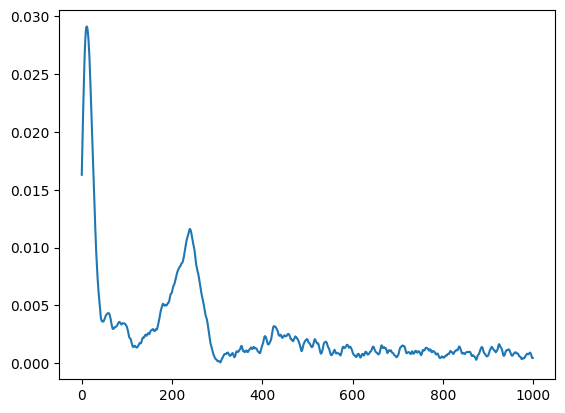

In [12]:
plt.plot(X_combined[0], label=f"healthy {0}")

In [13]:
WAVENUMBERS = np.linspace(0, 1000, X_combined.shape[1])

Calculated mean spectrum for 'healthy'. Shape: (1000,)
Calculated mean spectrum for 'sick'. Shape: (1000,)


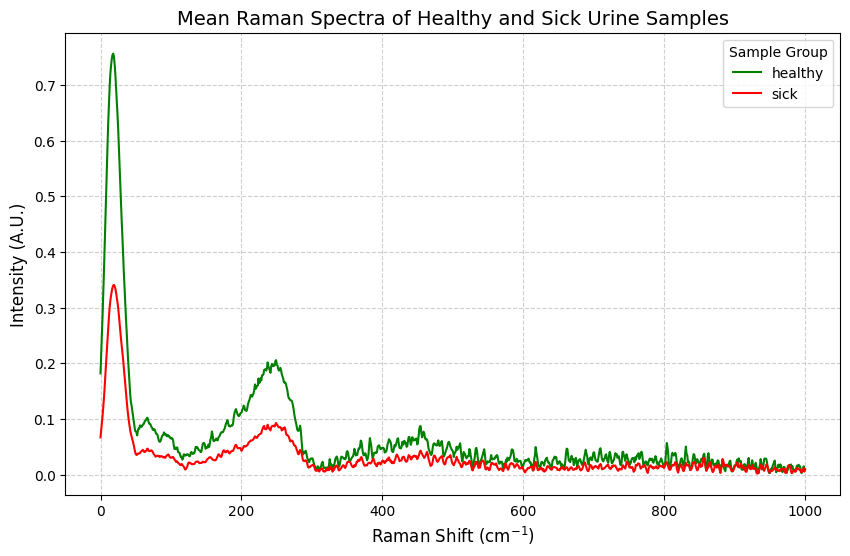

In [14]:
# 1a. Identify unique labels
unique_labels = np.unique(y_combined)

# Dictionary to store the mean spectrum for each label
mean_spectra = {}

for label in unique_labels:
    # Create a mask to select only spectra belonging to the current label
    mask = (y_combined == label)
    
    # Select the spectra for this label
    spectra_group = X_combined[mask]
    
    # Calculate the mean (average) intensity across all samples in the group (axis=0)
    mean_spectrum = np.mean(spectra_group, axis=0)
    
    mean_spectra[label] = mean_spectrum
    print(f"Calculated mean spectrum for '{label}'. Shape: {mean_spectrum.shape}")

# --- 2. Plotting the Stacked Mean Spectra ---

# Define colors for clarity
color_map = {'healthy': 'green', 'sick': 'red'}

# Create the figure and axes
plt.figure(figsize=(10, 6))

# Plot each mean spectrum
for label, mean_intensity in mean_spectra.items():
    plt.plot(
        WAVENUMBERS, 
        mean_intensity, 
        label=label, 
        color=color_map.get(label, 'blue') # Use default blue if label not in map
    )

# --- 3. Add Titles and Labels ---

# Title of the plot
plt.title('Mean Raman Spectra of Healthy and Sick Urine Samples', fontsize=14)

# X-axis label (Raman Shift)
plt.xlabel(r'Raman Shift ($\mathrm{cm^{-1}}$)', fontsize=12)

# Y-axis label (Intensity)
plt.ylabel('Intensity (A.U.)', fontsize=12) # A.U. stands for Arbitrary Units

# Add legend to distinguish the lines
plt.legend(title="Sample Group")

# Add a grid for better readability
plt.grid(True, linestyle='--', alpha=0.6)

# Show the plot
plt.show()